**SQL: DATA EXTRACTION AND ANALYSIS**

4.1 – Import Required Libraries

In [1]:
# 4.1 – Import Required Libraries

import pandas as pd
import numpy as np
import sqlite3

print("All libraries imported successfully.")

All libraries imported successfully.


4.2 – Upload the Cleaned Hotel Booking Dataset

In [2]:
# 4.2 – Upload Cleaned Hotel Booking Dataset

from google.colab import files

uploaded = files.upload()

Saving Hotel_Booking_Cleaned.csv to Hotel_Booking_Cleaned (1).csv


4.3 – Load the Cleaned Dataset

In [3]:
# 4.3 – Load Cleaned Hotel Booking Dataset

df_sql = pd.read_csv('Hotel_Booking_Cleaned.csv')

print("Dataset loaded successfully.")

print("Total Rows:", df_sql.shape[0])
print("Total Columns:", df_sql.shape[1])

display(df_sql.head())

Dataset loaded successfully.
Total Rows: 87395
Total Columns: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


4.4 – Check Available Dataset Columns

In [4]:
# 4.4 – Check Available Dataset Columns

print("Available Dataset Columns:")

for column in df_sql.columns:
    print(column)

Available Dataset Columns:
hotel
is_canceled
lead_time
arrival_date_year
arrival_date_month
arrival_date_week_number
arrival_date_day_of_month
stays_in_weekend_nights
stays_in_week_nights
adults
children
babies
meal
country
market_segment
distribution_channel
is_repeated_guest
previous_cancellations
previous_bookings_not_canceled
reserved_room_type
assigned_room_type
booking_changes
deposit_type
agent
company
days_in_waiting_list
customer_type
adr
required_car_parking_spaces
total_of_special_requests
reservation_status
reservation_status_date


4.5 – Prepare Related Tables for SQL Database

In [5]:
# 4.5 – Prepare Related Tables for SQL Database

dimension_columns = {
    'Hotels': ('hotel_id', 'hotel'),
    'Segments': ('segment_id', 'market_segment'),
    'Channels': ('channel_id', 'distribution_channel'),
    'Meals': ('meal_id', 'meal'),
    'Room_Types': ('room_type_id', 'reserved_room_type'),
    'Customer_Types': ('customer_type_id', 'customer_type')
}

dimension_data = {}

booking_data = df_sql.copy()

for table, (id_column, source_column) in dimension_columns.items():

    values = (
        booking_data[source_column]
        .fillna('Unknown')
        .astype(str)
        .unique()
    )

    dimension_df = pd.DataFrame({
        id_column: range(1, len(values) + 1),
        source_column: values
    })

    dimension_data[table] = dimension_df

    value_map = dict(
        zip(values, range(1, len(values) + 1))
    )

    booking_data[id_column] = (
        booking_data[source_column]
        .fillna('Unknown')
        .astype(str)
        .map(value_map)
    )

print("Six related lookup tables prepared successfully.")

for table, data in dimension_data.items():
    print(table, ":", len(data), "records")

Six related lookup tables prepared successfully.
Hotels : 2 records
Segments : 8 records
Channels : 5 records
Meals : 5 records
Room_Types : 10 records
Customer_Types : 4 records


4.6 – Create SQLite Database Connection

In [6]:
# 4.6 – Create SQLite Database Connection

conn = sqlite3.connect('Hotel_Revenue_Management.db')

conn.execute("PRAGMA foreign_keys = ON")

print("SQLite database connection established successfully.")

SQLite database connection established successfully.


4.7 – Create Database Tables

In [7]:
# 4.7 – Create Database Tables

conn.executescript("""

CREATE TABLE IF NOT EXISTS Hotels (
    hotel_id INTEGER PRIMARY KEY,
    hotel TEXT UNIQUE NOT NULL
);

CREATE TABLE IF NOT EXISTS Segments (
    segment_id INTEGER PRIMARY KEY,
    market_segment TEXT UNIQUE NOT NULL
);

CREATE TABLE IF NOT EXISTS Channels (
    channel_id INTEGER PRIMARY KEY,
    distribution_channel TEXT UNIQUE NOT NULL
);

CREATE TABLE IF NOT EXISTS Meals (
    meal_id INTEGER PRIMARY KEY,
    meal TEXT UNIQUE NOT NULL
);

CREATE TABLE IF NOT EXISTS Room_Types (
    room_type_id INTEGER PRIMARY KEY,
    reserved_room_type TEXT UNIQUE NOT NULL
);

CREATE TABLE IF NOT EXISTS Customer_Types (
    customer_type_id INTEGER PRIMARY KEY,
    customer_type TEXT UNIQUE NOT NULL
);

CREATE TABLE IF NOT EXISTS Bookings (
    booking_id INTEGER PRIMARY KEY,
    hotel_id INTEGER,
    segment_id INTEGER,
    channel_id INTEGER,
    meal_id INTEGER,
    room_type_id INTEGER,
    customer_type_id INTEGER,
    lead_time INTEGER,
    arrival_date_year INTEGER,
    arrival_date_month TEXT,
    adults INTEGER,
    children REAL,
    babies INTEGER,
    stays_in_weekend_nights INTEGER,
    stays_in_week_nights INTEGER,
    adr REAL,
    total_of_special_requests INTEGER,
    required_car_parking_spaces INTEGER,
    is_canceled INTEGER,
    country TEXT,

    FOREIGN KEY (hotel_id) REFERENCES Hotels(hotel_id),
    FOREIGN KEY (segment_id) REFERENCES Segments(segment_id),
    FOREIGN KEY (channel_id) REFERENCES Channels(channel_id),
    FOREIGN KEY (meal_id) REFERENCES Meals(meal_id),
    FOREIGN KEY (room_type_id) REFERENCES Room_Types(room_type_id),
    FOREIGN KEY (customer_type_id) REFERENCES Customer_Types(customer_type_id)
);

""")

print("All seven database tables created successfully.")

All seven database tables created successfully.


4.8 – Insert Records into Database Tables

In [8]:
# 4.8 – Insert Records into Database Tables

for table, dimension_df in dimension_data.items():

    dimension_df.to_sql(
        table,
        conn,
        if_exists='append',
        index=False
    )

booking_columns = [
    'hotel_id',
    'segment_id',
    'channel_id',
    'meal_id',
    'room_type_id',
    'customer_type_id',
    'lead_time',
    'arrival_date_year',
    'arrival_date_month',
    'adults',
    'children',
    'babies',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adr',
    'total_of_special_requests',
    'required_car_parking_spaces',
    'is_canceled',
    'country'
]

bookings_table = booking_data[booking_columns].copy()

# Create a technical booking ID for database purposes
bookings_table.insert(
    0,
    'booking_id',
    range(1, len(bookings_table) + 1)
)

bookings_table.to_sql(
    'Bookings',
    conn,
    if_exists='append',
    index=False
)

print("All records inserted successfully.")
print("Total Booking Records:", len(bookings_table))

All records inserted successfully.
Total Booking Records: 87395


4.9 – Verify Database Tables and Records

In [9]:
# 4.9 – Verify Database Tables and Records

tables = pd.read_sql_query("""

SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;

""", conn)

print("DATABASE TABLES:")

display(tables)

table_names = [
    'Bookings',
    'Hotels',
    'Segments',
    'Channels',
    'Meals',
    'Room_Types',
    'Customer_Types'
]

print("RECORD COUNT IN EACH TABLE:")

for table in table_names:

    count = pd.read_sql_query(
        f"SELECT COUNT(*) AS Total_Records FROM {table}",
        conn
    )

    print(table)
    display(count)

print("FOREIGN KEY CHECK:")

foreign_key_check = pd.read_sql_query(
    "PRAGMA foreign_key_check;",
    conn
)

display(foreign_key_check)

DATABASE TABLES:


,name
0,Bookings
1,Channels
2,Customer_Types
3,Hotels
4,Meals
5,Room_Types
6,Segments


RECORD COUNT IN EACH TABLE:
Bookings


,Total_Records
0,87395


Hotels


,Total_Records
0,2


... (8 outputs left out)

Customer_Types


,Total_Records
0,4


FOREIGN KEY CHECK:


,table,rowid,parent,fkid


4.10 – Retrieve and Sort Hotel Bookings

In [10]:
# 4.10 – Retrieve and Sort Hotel Bookings

query_4_10 = pd.read_sql_query("""
SELECT
    booking_id,
    adr,
    lead_time,
    adults,
    hotel_id
FROM Bookings
ORDER BY adr DESC
LIMIT 10;
""", conn)

display(query_4_10)

,booking_id,adr,lead_time,adults,hotel_id
0,38749,5400.00,35,2,2
1,80728,510.00,0,1,2
2,11661,508.00,1,2,1
3,74461,451.50,81,2,2
4,9985,450.00,378,2,1
5,10215,437.00,59,2,1
6,33093,426.25,31,2,1
7,33489,402.00,104,3,1
8,33056,397.38,26,3,1
9,10151,392.00,116,2,1


4.11 – Filter Bookings Using WHERE, AND, OR and BETWEEN

In [11]:
# 4.11 – Filter Bookings Using WHERE, AND, OR and BETWEEN

query_4_11 = pd.read_sql_query("""
SELECT
    booking_id,
    adr,
    lead_time,
    adults,
    children
FROM Bookings
WHERE adr BETWEEN 50 AND 200
AND lead_time >= 30
AND (adults >= 2 OR children > 0)
ORDER BY adr DESC;
""", conn)

display(query_4_11.head(20))

,booking_id,adr,lead_time,adults,children
0,968,200.0,63,2,1.0
1,5236,200.0,181,2,2.0
2,5271,200.0,161,2,2.0
3,5293,200.0,169,2,2.0
4,5406,200.0,59,2,0.0
5,9097,200.0,368,2,0.0
6,9244,200.0,109,2,2.0
7,9252,200.0,159,2,1.0
8,9348,200.0,202,2,2.0
9,9388,200.0,110,2,0.0


4.12 – Filter Using IN and LIKE

In [12]:
# 4.12 – Filter Using IN and LIKE

query_4_12 = pd.read_sql_query("""
SELECT
    b.booking_id,
    s.market_segment,
    b.country,
    b.adr
FROM Bookings b
INNER JOIN Segments s
    ON b.segment_id = s.segment_id
WHERE s.market_segment IN ('Online TA', 'Offline TA/TO')
AND s.market_segment LIKE '%TA%'
AND b.country LIKE 'P%'
ORDER BY b.adr DESC
LIMIT 20;
""", conn)

display(query_4_12)

,booking_id,market_segment,country,adr
0,38749,Offline TA/TO,PRT,5400.00
1,9985,Online TA,PRT,450.00
2,33438,Online TA,PRT,392.00
3,7304,Online TA,PRT,384.00
4,33872,Online TA,PRT,383.00
5,7336,Online TA,PRT,382.00
6,10297,Online TA,PRT,378.00
7,32564,Online TA,PRT,377.00
8,33033,Online TA,PRT,372.00
9,21900,Online TA,PRT,359.00


4.13 – Handle Missing Values Using IS NULL and COALESCE

In [13]:
# 4.13 – Handle Missing Values Using IS NULL and COALESCE

query_4_13 = pd.read_sql_query("""
SELECT
    COALESCE(country, 'Unknown') AS Country_Name,
    COUNT(*) AS Total_Bookings
FROM Bookings
GROUP BY COALESCE(country, 'Unknown')
ORDER BY Total_Bookings DESC;
""", conn)

display(query_4_13)

,Country_Name,Total_Bookings
0,PRT,27453
1,GBR,10432
2,FRA,8837
3,ESP,7252
4,DEU,5387
...,...,...
173,BFA,1
174,BDI,1
175,ATF,1
176,ASM,1


In [14]:
# 4.13 (Additional) – Count Missing Country Values

missing_country_sql = pd.read_sql_query("""
SELECT
    COUNT(*) AS Total_Records,
    SUM(
        CASE WHEN country IS NULL THEN 1 ELSE 0 END
    ) AS Missing_Country_Records
FROM Bookings;
""", conn)

display(missing_country_sql)

,Total_Records,Missing_Country_Records
0,87395,0


4.14 – Perform SQL Aggregate Functions

In [15]:
# 4.14 – SQL Aggregate Functions

query_4_14 = pd.read_sql_query("""
SELECT
    COUNT(*) AS Total_Bookings,
    SUM(adults + children + babies) AS Total_Guest_Count,
    ROUND(AVG(adr), 2) AS Average_ADR,
    ROUND(MIN(adr), 2) AS Minimum_ADR,
    ROUND(MAX(adr), 2) AS Maximum_ADR
FROM Bookings;
""", conn)

display(query_4_14)

,Total_Bookings,Total_Guest_Count,Average_ADR,Minimum_ADR,Maximum_ADR
0,87395,176997.0,106.34,0.0,5400.0


4.15 – Use GROUP BY and HAVING

In [16]:
# 4.15 – GROUP BY and HAVING

query_4_15 = pd.read_sql_query("""
SELECT
    s.market_segment,
    COUNT(*) AS Total_Bookings,
    ROUND(AVG(b.adr), 2) AS Average_ADR
FROM Bookings b
INNER JOIN Segments s
    ON b.segment_id = s.segment_id
GROUP BY s.market_segment
HAVING COUNT(*) >= 1000
ORDER BY Average_ADR DESC;
""", conn)

display(query_4_15)

,market_segment,Total_Bookings,Average_ADR
0,Online TA,51618,118.17
1,Direct,11804,116.58
2,Offline TA/TO,13889,81.76
3,Groups,4941,74.88
4,Corporate,4212,68.15


4.16 – Perform INNER JOIN

In [17]:
# 4.16 – INNER JOIN

query_4_16 = pd.read_sql_query("""
SELECT
    h.hotel AS Hotel_Type,
    COUNT(*) AS Total_Bookings,
    ROUND(AVG(b.adr), 2) AS Average_ADR
FROM Bookings b
INNER JOIN Hotels h
    ON b.hotel_id = h.hotel_id
GROUP BY h.hotel
ORDER BY Average_ADR DESC;
""", conn)

display(query_4_16)

,Hotel_Type,Total_Bookings,Average_ADR
0,City Hotel,53428,110.99
1,Resort Hotel,33967,99.03


4.17 – Perform LEFT JOIN

In [18]:
# 4.17 – LEFT JOIN

query_4_17 = pd.read_sql_query("""
SELECT
    s.market_segment,
    COUNT(b.booking_id) AS Total_Bookings,
    ROUND(AVG(b.adr), 2) AS Average_ADR
FROM Segments s
LEFT JOIN Bookings b
    ON s.segment_id = b.segment_id
GROUP BY s.market_segment
ORDER BY Total_Bookings DESC;
""", conn)

display(query_4_17)

,market_segment,Total_Bookings,Average_ADR
0,Online TA,51618,118.17
1,Offline TA/TO,13889,81.76
2,Direct,11804,116.58
3,Groups,4941,74.88
4,Corporate,4212,68.15
5,Complementary,702,3.05
6,Aviation,227,100.17
7,Undefined,2,15.00


4.18 – Apply CASE WHEN Function

In [19]:
# 4.18 – CASE WHEN for ADR Classification

adr_q1 = float(df_sql['adr'].quantile(0.25))
adr_q3 = float(df_sql['adr'].quantile(0.75))

query_4_18 = pd.read_sql_query(f"""
SELECT
    CASE
        WHEN adr <= {adr_q1} THEN 'Lower ADR Group'
        WHEN adr <= {adr_q3} THEN 'Middle ADR Group'
        ELSE 'Upper ADR Group'
    END AS ADR_Category,
    COUNT(*) AS Total_Bookings,
    ROUND(AVG(adr), 2) AS Average_ADR
FROM Bookings
GROUP BY ADR_Category
ORDER BY Average_ADR;
""", conn)

display(query_4_18)

,ADR_Category,Total_Bookings,Average_ADR
0,Lower ADR Group,21876,48.77
1,Middle ADR Group,43702,100.06
2,Upper ADR Group,21817,176.64


4.19 – Analyse ADR by Hotel Type and Market Segment

In [20]:
# 4.19 – Hotel Type and Market Segment Analysis

query_4_19 = pd.read_sql_query("""
SELECT
    h.hotel AS Hotel_Type,
    s.market_segment AS Market_Segment,
    COUNT(*) AS Total_Bookings,
    ROUND(AVG(b.adr), 2) AS Average_ADR
FROM Bookings b
INNER JOIN Hotels h
    ON b.hotel_id = h.hotel_id
INNER JOIN Segments s
    ON b.segment_id = s.segment_id
GROUP BY h.hotel, s.market_segment
ORDER BY h.hotel, Average_ADR DESC;
""", conn)

display(query_4_19)

,Hotel_Type,Market_Segment,Total_Bookings,Average_ADR
0,City Hotel,Direct,5559,120.85
1,City Hotel,Online TA,34994,119.78
2,City Hotel,Aviation,227,100.17
3,City Hotel,Offline TA/TO,7271,87.28
4,City Hotel,Groups,2635,84.75
5,City Hotel,Corporate,2227,82.69
6,City Hotel,Undefined,2,15.00
7,City Hotel,Complementary,513,2.75
8,Resort Hotel,Online TA,16624,114.78
9,Resort Hotel,Direct,6245,112.78


4.20 – Analyse Monthly ADR by Hotel Type

In [21]:
# 4.20 – Monthly ADR Analysis by Hotel Type

query_4_20 = pd.read_sql_query("""
SELECT
    h.hotel AS Hotel_Type,
    b.arrival_date_year AS Arrival_Year,
    b.arrival_date_month AS Arrival_Month,
    COUNT(*) AS Total_Bookings,
    ROUND(AVG(b.adr), 2) AS Average_ADR
FROM Bookings b
INNER JOIN Hotels h
    ON b.hotel_id = h.hotel_id
GROUP BY
    h.hotel,
    b.arrival_date_year,
    b.arrival_date_month
ORDER BY
    b.arrival_date_year,
    CASE b.arrival_date_month
        WHEN 'January' THEN 1
        WHEN 'February' THEN 2
        WHEN 'March' THEN 3
        WHEN 'April' THEN 4
        WHEN 'May' THEN 5
        WHEN 'June' THEN 6
        WHEN 'July' THEN 7
        WHEN 'August' THEN 8
        WHEN 'September' THEN 9
        WHEN 'October' THEN 10
        WHEN 'November' THEN 11
        WHEN 'December' THEN 12
    END;
""", conn)

display(query_4_20)

,Hotel_Type,Arrival_Year,Arrival_Month,Total_Bookings,Average_ADR
0,City Hotel,2015,July,395,66.81
1,Resort Hotel,2015,July,1279,126.48
2,City Hotel,2015,August,1107,82.98
3,Resort Hotel,2015,August,1346,155.90
4,City Hotel,2015,September,1672,106.80
5,Resort Hotel,2015,September,1167,89.97
6,City Hotel,2015,October,1559,95.09
7,Resort Hotel,2015,October,1141,56.84
8,City Hotel,2015,November,797,73.90
9,Resort Hotel,2015,November,868,45.77


**PART 4 – SQL AND PYTHON INTEGRATION**

4.21 – Export SQL Results into Python

In [22]:
# 4.21 – Export SQL Results into Python

sql_python_data = pd.read_sql_query("""
SELECT
    h.hotel AS Hotel_Type,
    s.market_segment AS Market_Segment,
    ROUND(AVG(b.adr), 2) AS Average_ADR
FROM Bookings b
INNER JOIN Hotels h
    ON b.hotel_id = h.hotel_id
INNER JOIN Segments s
    ON b.segment_id = s.segment_id
GROUP BY
    h.hotel,
    s.market_segment;
""", conn)

print("SQL results successfully loaded into Python.")

display(sql_python_data)

SQL results successfully loaded into Python.


,Hotel_Type,Market_Segment,Average_ADR
0,City Hotel,Aviation,100.17
1,City Hotel,Complementary,2.75
2,City Hotel,Corporate,82.69
3,City Hotel,Direct,120.85
4,City Hotel,Groups,84.75
5,City Hotel,Offline TA/TO,87.28
6,City Hotel,Online TA,119.78
7,City Hotel,Undefined,15.00
8,Resort Hotel,Complementary,3.87
9,Resort Hotel,Corporate,51.84


4.22 – Visualise SQL Results Using Python

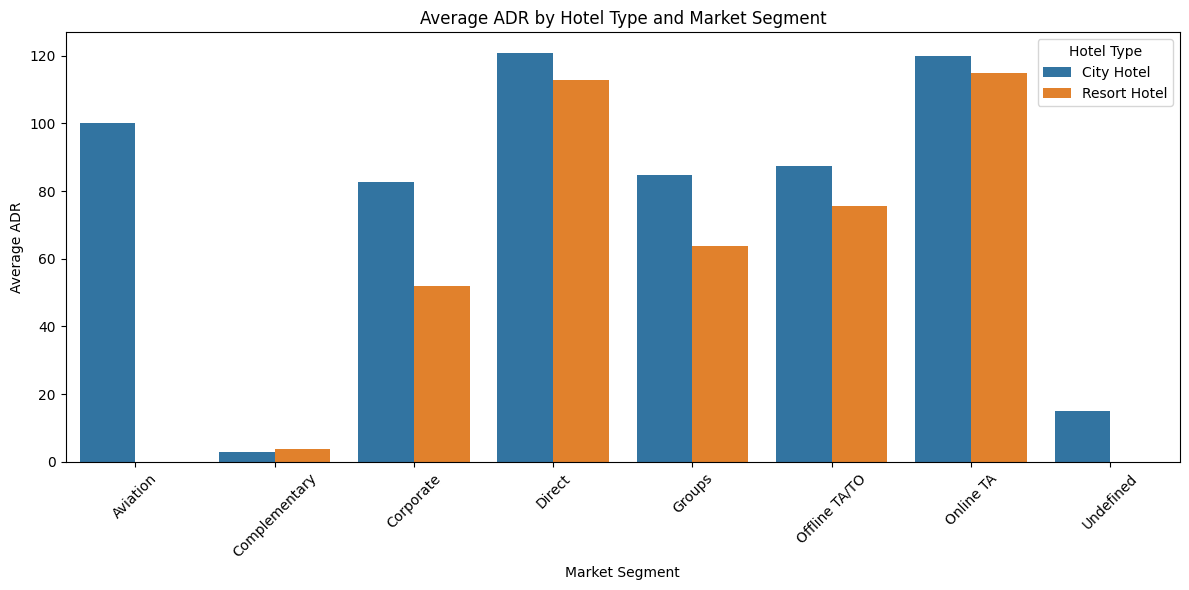

In [24]:
# 4.22 – Visualise SQL Results Using Python

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=sql_python_data,
    x='Market_Segment',
    y='Average_ADR',
    hue='Hotel_Type',
    errorbar=None
)

plt.title("Average ADR by Hotel Type and Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Average ADR")
plt.xticks(rotation=45)
plt.legend(title="Hotel Type")

plt.tight_layout()
plt.show()

4.23 – Export SQL Query Results

In [25]:
# 4.23 – Export SQL Query Results

query_4_19.to_csv(
    'Hotel_SQL_Query_Results.csv',
    index=False
)

sql_python_data.to_csv(
    'Hotel_SQL_Python_Results.csv',
    index=False
)

print("SQL query results exported successfully.")

SQL query results exported successfully.
